# Actividad: Red de Hopfield para Clasificación de Dígitos MNIST

**Asignatura:** Aprendizaje Automático

**Nombre del equipo:** Néstor y Gonzalo

| # | Nombre completo | Matrícula / ID |
|---|---|---|
| 1 | Néstor Moreno Muñoz | 9406872 |
| 2 | Gonzalo Artíñano Márquez | 9401046 |


**Fecha de entrega:** 23/10/2026

**Repositorio del código:** https://github.com/nestorm1/redes-hopfield-mnist

---

**Objetivo.** Implementar una red de Hopfield (modelo de memoria asociativa) capaz de clasificar dígitos manuscritos del conjunto MNIST, evaluando su desempeño sobre un subconjunto reducido de 100 imágenes, y analizar las capacidades y limitaciones de las redes recurrentes con dinámica de energía frente a problemas de reconocimiento de patrones.

## 1. Introducción

Una memoria asociativa es un sistema capaz de recuperar un patrón completo a partir de una versión incompleta o con ruido de ese mismo patrón. Es decir, no se accede a la información mediante una dirección como en una memoria normal, sino por su contenido: si le damos a la red algo parecido a lo que tiene guardado, nos devuelve el patrón original.

La red de Hopfield (Hopfield, 1982) es el modelo más conocido de memoria asociativa. Es una red recurrente en la que todas las neuronas están conectadas entre sí. Cada neurona solo puede valer -1 o +1, los pesos son simétricos ($w_{ij} = w_{ji}$) y no hay autoconexiones ($w_{ii} = 0$). Para guardar los patrones se usa la regla de Hebb:

$$w_{ij} = \frac{1}{N}\sum_{s=1}^{P} x_i^{(s)}\, x_j^{(s)}$$

Después, la red va actualizando las neuronas con la función signo:

$$x_i(t+1) = \operatorname{sgn}\Big(\sum_j w_{ij}\, x_j(t) - \theta_i\Big)$$

Si los pesos son simétricos y las neuronas se actualizan de una en una (dinámica asíncrona), se puede definir una función de energía:

$$E(\mathbf{x}) = -\frac{1}{2}\sum_{i,j} w_{ij}\, x_i x_j + \sum_i \theta_i\, x_i$$

Esta energía nunca aumenta mientras la red evoluciona, así que la red siempre acaba en un mínimo local, al que llamamos atractor (Haykin, 2009). La idea es que los patrones guardados sean esos mínimos, de forma que si empezamos en un estado parecido a un patrón, la red acabe cayendo en él.

El problema es que la red no puede guardar todos los patrones que queramos. Para patrones aleatorios, la capacidad teórica es de aproximadamente $0.138\,N$ patrones (Haykin, 2009). Si se guardan más, los patrones se interfieren entre ellos, dejan de ser estables y aparecen estados espurios, que son mínimos de energía que no corresponden a ningún patrón guardado.

En esta práctica vamos a usar una red de Hopfield para clasificar dígitos del conjunto MNIST (LeCun et al., 1998). Guardamos en la red las imágenes de entrenamiento, iniciamos la red con cada imagen de test y le asignamos la clase del patrón guardado más parecido al estado final. Además, estudiamos cómo afecta el ruido y comparamos los resultados con la capacidad teórica de la red.

## 2. Desarrollo

En esta sección está todo el código comentado, con la explicación de cada parte y sus resultados. Lo hemos hecho en Python, usando numpy para las operaciones con matrices, matplotlib para las gráficas y scikit-learn para descargar MNIST, hacer la división estratificada y calcular las métricas. Hemos fijado la semilla a 42 para que los resultados se puedan reproducir.

Las partes del desarrollo son:
- 2.1 Selección y preprocesamiento del dataset
- 2.2 División del conjunto
- 2.3 Implementación de la red de Hopfield (regla de Hebb, dinámica asíncrona, energía y criterio de convergencia)
- 2.4 Clasificación y resultados (accuracy, matriz de confusión, gráficas de energía y patrones recuperados)
- 2.5 Análisis con ruido
- 2.6 Capacidad de almacenamiento

### 2.1 Selección y preprocesamiento del dataset
#### En esta sección, se va a extraer un subconjunto de 100 imágenes de MNIST que contenga 10 instancias por cada dígito (0-9)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml # descargar conjunto de datos públicos de openml.org
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

En este bloque de código, vamos a cargar el conjunto MNIST_784 porque cada imagen de 28x28 se guarda en un vector de 28·28 = 784.  
- return_X_y = True -> nos permite que nos devuelva una matriz de forma (70000,784) donde cada fila es una imagen y cada columna un píxel, con valores de 0 a 255 para la X. Para la y un vector de 70000 etiquetas, que dicen qué dígito es cada imagen.  
- as_frame = false -> arrays de NumPy.  

In [2]:
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

Ahora vamos a seleccionar las 10 imágenes por dígito.  
- y == d -> crea un array de True/False.  
- np.where(...)[0] -> devuelve los índices donde hay True.  
- rng.choice(idx_d, 10, replace=False) -> elige 10 de esos índices al azar, sin reemplazo, para que no salgan repetidas las imágenes.  
- indices.extend(...) -> añade esos 10 índices a la lista.

In [3]:
n_por_digito = 10
rng = np.random.default_rng(42)

indices = []
for d in range(10):
    idx_d = np.where(y == d)[0]
    indices.extend(rng.choice(idx_d, n_por_digito, replace=False))
indices = np.array(indices)

Una vez tenemos las 100 posiciones ordenadas, necesitamos poder usarlo como índice.

In [4]:
X_sub = X[indices]
y_sub = y[indices]

print(X_sub.shape, y_sub.shape)
print(np.bincount(y_sub))

(100, 784) (100,)
[10 10 10 10 10 10 10 10 10 10]


Vamos a visualizar las imágenes.  
- axes.ravel() -> convierte la cuadrícula 10x10 de ejes en una lista plana de 100, para recorrerla junto a las imágenes.  
- zip(...) -> recorre a la vez cada eje, cada imagen y su etiqueta. 
- img.reshape(28,28) -> la imagen está aplanada, se reconstruye 28x28.  
- ax.axis(off) -> quita los ejes y números.   


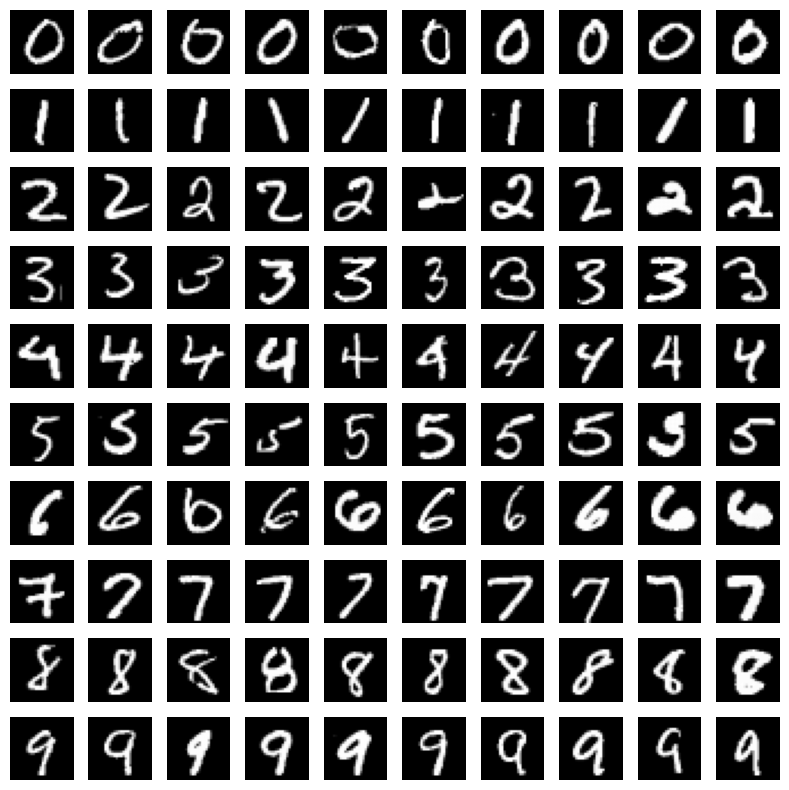

In [5]:
fig, axes = plt.subplots(10, 10, figsize=(8,8))

for ax, img, lbl in zip(axes.ravel(), X_sub, y_sub):
    ax.imshow(img.reshape(28,28), cmap ='gray')
    ax.axis('off')

plt.tight_layout()
plt.show()

#### Ahora debemos binarizar cada imagen para poder aplicar la red de Hopfield (no la vectorizamos a 784 porque ya lo tenemos así)
- X_sub / 255 -> pasa los píxeles de 0-255 a 0-1.
- > 0.5 -> umbral del enunciado: los píxeles por encima pasan a +1 y el resto a -1.


In [6]:
X_bin = np.where(X_sub / 255 > 0.5, 1, -1)

### 2.2 División del conjunto
#### Ahora debemos dividir el subconjunto en training set y en test set con proporciones de 0.7 y 0.3. Además, la división debe ser estratificada con 7 instancias por dígito en entrenamiento y 3 en prueba. Por último, fijamos una semilla aleatoria para garantizar la reproducibilidad.

- X_bin, y_sub -> lo que se divide, las imágenes ya binarizadas y sus etiquetas.
- stratify=y_sub -> división estratificada, mantiene en cada conjunto la misma proporción de cada clase que en el total. 

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_bin, y_sub,
    test_size=0.3,
    stratify=y_sub,
    random_state=42
)

print(X_train.shape, X_test.shape)
print("Train por dígito:", np.bincount(y_train))
print("Test por dígito:", np.bincount(y_test))

(70, 784) (30, 784)
Train por dígito: [7 7 7 7 7 7 7 7 7 7]
Test por dígito: [3 3 3 3 3 3 3 3 3 3]


### 2.3 Implementación de la red de Hopfield
#### Se deben realizar tres cosas: 1. entrenar la red usando la regla de Hebb, 2. implementar la dinámica asíncrona de actualización y 3. definir una función de energía y monitorear su decremento durante la convergencia.


- entrenar_hebb -> W = (1/N)·Σ x·xᵀ con la diagonal a 0 (sin autoconexiones).
- signo -> función sgn con el convenio sgn(0) = +1.
- energia -> E = -½·sᵀWs + θᵀs. Con dinámica asíncrona nunca aumenta.
- evolucionar_asincrono -> actualiza las neuronas de una en una: xᵢ = sgn(Σⱼ wᵢⱼxⱼ - θᵢ). Criterio de convergencia: un barrido completo (784 neuronas) sin ningún cambio.
- recuperar -> la misma dinámica sin guardar la energía; es más rápida y se usa en los experimentos.


In [8]:
def entrenar_hebb(patrones):
    '''
    Entrena la red de Hopfield con la regla de Hebb.

    w_ij = (1/N) · Σ_s x_i^(s) · x_j^(s),   w_ii = 0
    '''
    P = np.asarray(patrones, dtype=float)
    N = P.shape[1]
    W = (P.T @ P)/N # suma de productos exteriores de p·p^T
    np.fill_diagonal(W, 0) # sin autoconexiones
    return W

def signo(h):
    """Función signo con el convenio sgn(0) = +1."""
    return 1 if h >= 0 else -1

def energia(W,s, theta):
    """Energía de Hopfield del estado s: E = -1/2 · sᵀWs + θᵀs."""
    return -0.5 * s @ W @ s + theta @ s

def evolucionar_asincrono(W, estado_inicial, theta=None, max_barridos=10):
    '''
    Dinámica asíncrona: x_i(t+1) = sgn(Σ_j w_ij·x_j(t) - θ_i), una neurona cada vez.
    Se detiene cuando un barrido completo no cambia ninguna neurona o al llegar a max_barridos.
    '''
    s = np.asarray(estado_inicial, dtype=float).copy()
    n = len(s)
    if theta is None:
        theta = np.zeros(n)
    estados = [s.copy()]
    energias = [energia(W, s, theta)]

    for barrido in range(max_barridos):
        cambio = False
        for i in range(n):
            nuevo = signo(W[i] @ s - theta[i]) # Σⱼ wᵢⱼ xⱼ(t) - θᵢ
            if nuevo != s[i]:
                s[i] = nuevo
                cambio = True
            estados.append(s.copy())
            energias.append(energia(W, s, theta))
        if not cambio:
            break
    return estados, energias

def recuperar(W, estado_inicial, max_barridos=20):
    """Misma dinámica asíncrona (θ = 0), pero sin guardar estados ni energías.

    Es mucho más rápida; se usa en los experimentos con muchas ejecuciones.
    Devuelve solo el estado final.
    """
    s = np.asarray(estado_inicial, dtype=float).copy()
    for barrido in range(max_barridos):
        cambio = False
        for i in range(len(s)):
            nuevo = signo(W[i] @ s)
            if nuevo != s[i]:
                s[i] = nuevo
                cambio = True
        if not cambio:
            break
    return s

### 2.4 Clasificación y resultados
#### Ahora debemos para cada patrón del test set, inicializar la red y dejar evolucionar hasta converger.

- entrenar_hebb(X_train) -> almacena las 70 imágenes de entrenamiento, como pide el enunciado.
- El bucle: cada imagen de test es el estado inicial de la red y evolucionar_asincrono la deja evolucionar hasta un barrido sin cambios.
- distancia_hamming -> cuenta en cuántos píxeles se diferencian dos patrones.
- clasificar -> asigna la etiqueta de la imagen almacenada más cercana (menor distancia de Hamming) al estado final.


In [9]:
def distancia_hamming(estado, patrones):
    """Número de bits distintos entre `estado` y cada fila de `patrones`."""
    return np.sum(patrones != estado, axis=1)

def clasificar(estado_final, patrones_almacenados, etiquetas):
    """Devuelve la etiqueta del patrón almacenado más cercano (distancia de Hamming)."""
    return etiquetas[np.argmin(distancia_hamming(estado_final, patrones_almacenados))]


W = entrenar_hebb(X_train)
N = W.shape[0]

estados_finales = []
curvas_energia = []
predicciones = []

for x in X_test:
    estados, energias = evolucionar_asincrono(W, x)
    estados_finales.append(estados[-1])
    curvas_energia.append(energias)
    predicciones.append(clasificar(estados[-1], X_train, y_train))

estados_finales = np.array(estados_finales)
predicciones = np.array(predicciones)

print("Predicciones:", predicciones)
print("Reales:      ", y_test)
print("¿Energía decreciente en todas?", all(np.all(np.diff(e) <= 1e-9) for e in curvas_energia))

Predicciones: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Reales:       [6 8 4 2 1 5 8 9 5 0 7 1 4 9 2 5 0 9 3 7 3 1 6 4 3 0 7 6 8 2]
¿Energía decreciente en todas? True


#### Accuracy y matriz de confusión
- Cada fila es el dígito real y cada columna el predicho; la diagonal son los aciertos.



Accuracy global: 0.1


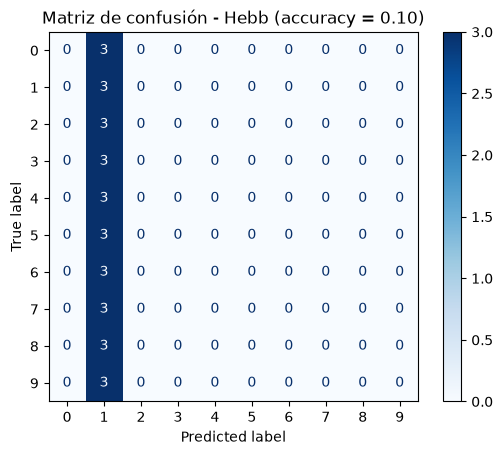

In [10]:
acc = accuracy_score(y_test, predicciones)
print("Accuracy global:", acc)

cm = confusion_matrix(y_test, predicciones, labels=range(10))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap='Blues')
plt.title(f"Matriz de confusión - Hebb (accuracy = {acc:.2f})")
plt.show()

#### Graficar la evolución de la energía y de los patrones recuperados.

Aquí vemos la evolución del patrón durante la convergencia.

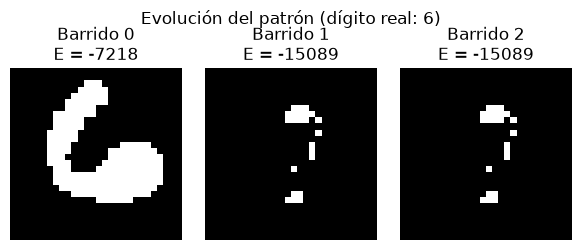

In [11]:
estados, energias = evolucionar_asincrono(W, X_test[0])
barridos = range(0, len(estados), N)

fig, axes = plt.subplots(1, len(barridos), figsize=(2 * len(barridos), 2.5))
for ax, k in zip(axes, barridos):
    ax.imshow(estados[k].reshape(28,28), cmap="gray")
    ax.set_title(f"Barrido {k // N}\nE = {energias[k]:.0f}")
    ax.axis("off")
plt.suptitle(f"Evolución del patrón (dígito real: {y_test[0]})")
plt.tight_layout()
plt.show()

La energía de las 30 imágenes

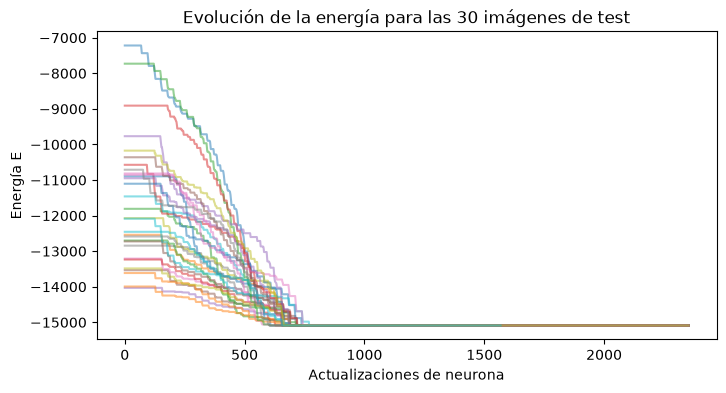

In [12]:
plt.figure(figsize=(8, 4))
for e in curvas_energia:
    plt.plot(e, alpha=0.5)
plt.xlabel("Actualizaciones de neurona")
plt.ylabel("Energía E")
plt.title("Evolución de la energía para las 30 imágenes de test")
plt.show()

Entrada y patrón recuperado de las 30 imágenes

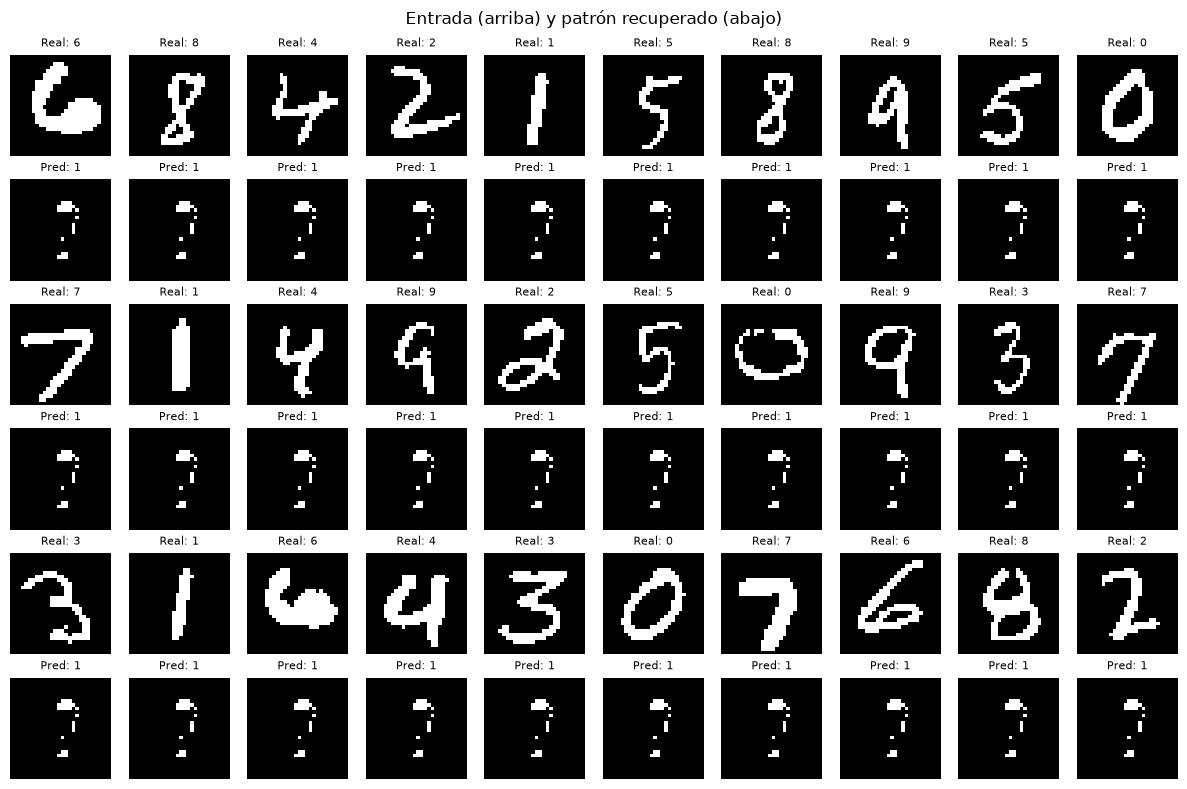

In [13]:
fig, axes = plt.subplots(6, 10, figsize=(12, 8))
for k in range(30):
    fila = (k // 10) * 2
    col = k % 10
    axes[fila, col].imshow(X_test[k].reshape(28, 28), cmap='gray')
    axes[fila, col].set_title(f"Real: {y_test[k]}", fontsize=8)
    axes[fila + 1, col].imshow(estados_finales[k].reshape(28, 28), cmap='gray')
    axes[fila + 1, col].set_title(f"Pred: {predicciones[k]}", fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle("Entrada (arriba) y patrón recuperado (abajo)")
plt.tight_layout()
plt.show()

### 2.5 Análisis con ruido
#### Se invierte un 5 %, 10 % y 20 % de los bits de las imágenes de test y se compara la regla de Hebb con la regla de proyección.
- invertir_bits -> invierte al azar una fracción p de los píxeles.
- entrenar_proyeccion -> regla de proyección (pseudoinversa): W = Xᵀ(XXᵀ)⁻¹X, tiene en cuenta las correlaciones entre patrones.


Ruido 0%: Hebb = 0.10   Proyección = 0.47


Ruido 5%: Hebb = 0.10   Proyección = 0.37


Ruido 10%: Hebb = 0.10   Proyección = 0.37


Ruido 20%: Hebb = 0.10   Proyección = 0.33


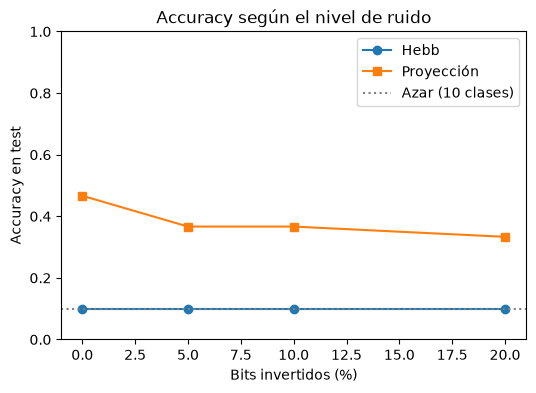

In [14]:
def invertir_bits(X, p, rng):
    """Devuelve una copia de X con una fracción p de bits invertidos al azar (+1 ↔ -1)."""
    X_ruido = X.copy()
    mascara = rng.random(X.shape) < p
    X_ruido[mascara] *= -1
    return X_ruido


def entrenar_proyeccion(patrones):
    """Regla de proyección (pseudoinversa): W = Xᵀ(XXᵀ)⁻¹X, con w_ii = 0.

    A diferencia de Hebb, tiene en cuenta las correlaciones entre patrones,
    de modo que cada patrón almacenado es un punto fijo aunque se parezcan entre sí.
    """
    P = np.asarray(patrones, dtype=float)
    W = P.T @ np.linalg.inv(P @ P.T) @ P
    np.fill_diagonal(W, 0)
    return W


def evaluar(W, X, patrones_almacenados, etiquetas):
    """Deja converger la red desde cada fila de X y clasifica el estado final."""
    return np.array([clasificar(recuperar(W, x), patrones_almacenados, etiquetas) for x in X])


W_proy = entrenar_proyeccion(X_train)

rng_ruido = np.random.default_rng(42)
niveles = [0, 0.05, 0.10, 0.20]
acc_hebb = []
acc_proy = []

for p in niveles:
    X_ruido = invertir_bits(X_test, p, rng_ruido)
    acc_hebb.append(accuracy_score(y_test, evaluar(W, X_ruido, X_train, y_train)))
    acc_proy.append(accuracy_score(y_test, evaluar(W_proy, X_ruido, X_train, y_train)))
    print(f"Ruido {p:.0%}: Hebb = {acc_hebb[-1]:.2f}   Proyección = {acc_proy[-1]:.2f}")

plt.figure(figsize=(6, 4))
plt.plot([p * 100 for p in niveles], acc_hebb, 'o-', label="Hebb")
plt.plot([p * 100 for p in niveles], acc_proy, 's-', label="Proyección")
plt.axhline(0.1, color='gray', linestyle=':', label="Azar (10 clases)")
plt.xlabel("Bits invertidos (%)")
plt.ylabel("Accuracy en test")
plt.title("Accuracy según el nivel de ruido")
plt.ylim(0, 1)
plt.legend()
plt.show()

#### Matriz de confusión de la proyección y ejemplos

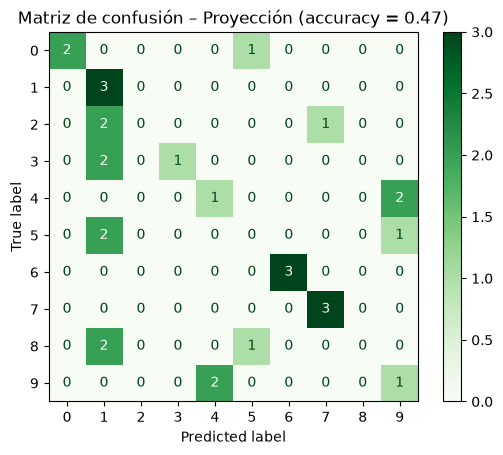

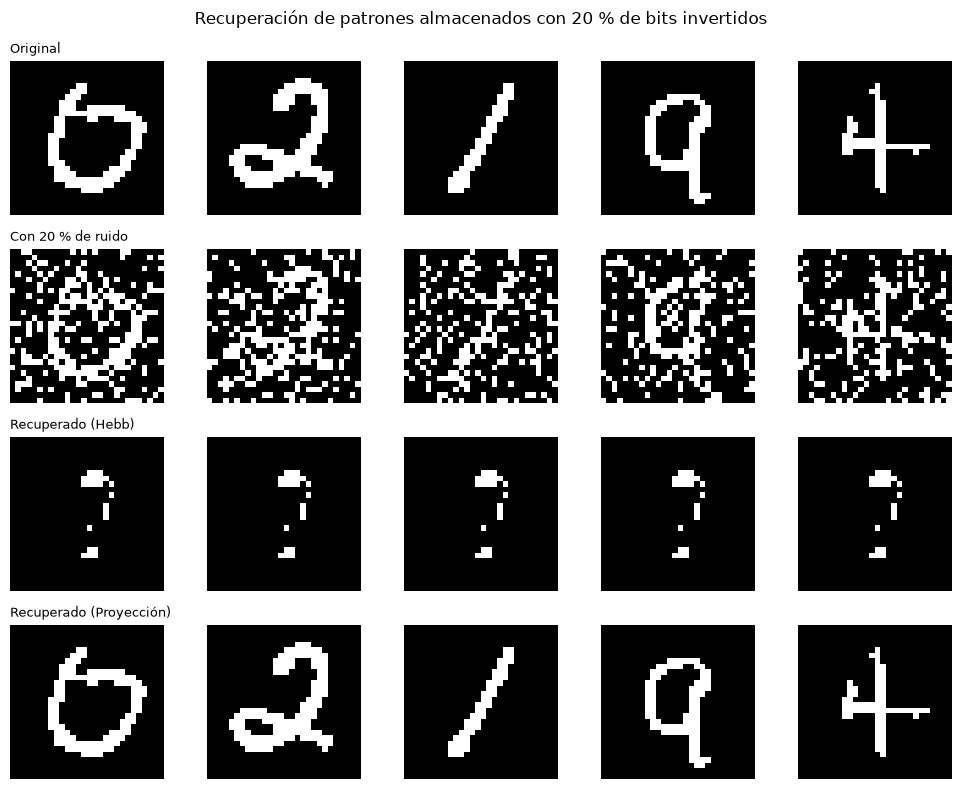

Patrones de entrenamiento que son puntos fijos: Hebb = 0%, Proyección = 100%


In [15]:
pred_proy = evaluar(W_proy, X_test, X_train, y_train)
cm_proy = confusion_matrix(y_test, pred_proy, labels=range(10))
ConfusionMatrixDisplay(cm_proy, display_labels=range(10)).plot(cmap='Greens')
plt.title(f"Matriz de confusión – Proyección (accuracy = {accuracy_score(y_test, pred_proy):.2f})")
plt.show()

ejemplos = [0, 7, 14, 21, 28]
X_orig = X_train[ejemplos]
X_ruidosos = invertir_bits(X_orig, 0.20, np.random.default_rng(0))

fig, axes = plt.subplots(4, len(ejemplos), figsize=(2 * len(ejemplos), 8))
titulos = ["Original", "Con 20 % de ruido", "Recuperado (Hebb)", "Recuperado (Proyección)"]
for j in range(len(ejemplos)):
    imagenes = [X_orig[j], X_ruidosos[j], recuperar(W, X_ruidosos[j]), recuperar(W_proy, X_ruidosos[j])]
    for f, img in enumerate(imagenes):
        axes[f, j].imshow(img.reshape(28, 28), cmap='gray')
        axes[f, j].axis('off')
        if j == 0:
            axes[f, j].set_title(titulos[f], fontsize=9, loc='left')
plt.suptitle("Recuperación de patrones almacenados con 20 % de bits invertidos")
plt.tight_layout()
plt.show()

estables_hebb = np.mean([np.array_equal(recuperar(W, x), x) for x in X_train])
estables_proy = np.mean([np.array_equal(recuperar(W_proy, x), x) for x in X_train])
print(f"Patrones de entrenamiento que son puntos fijos: Hebb = {estables_hebb:.0%}, Proyección = {estables_proy:.0%}")


### 2.6 Capacidad de almacenamiento
#### Discutir la capacidad de almacenamiento teórica (0.138 N) y compararla con los resultados obtenidos

- X_train[y_train == d] -> selecciona las 7 imágenes de entrenamiento del dígito d
- .mean(axis=0) hace la media píxel a píxel
- np.where(... >= 0, 1, -1) la vuelve a pasar a +-1: un píxel queda blanco si está encendido en la mayoría de las 7 imágenes.

(10, 784)


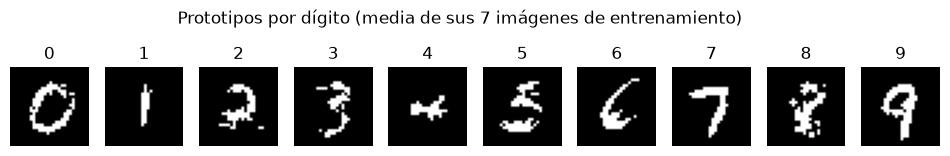

In [16]:
prototipos = np.array([
    np.where(X_train[y_train == d].mean(axis=0) >= 0, 1, -1)
    for d in range(10)
])
print(prototipos.shape)

fig, axes = plt.subplots(1, 10, figsize=(12,2))
for d, ax in enumerate(axes):
    ax.imshow(prototipos[d].reshape(28, 28), cmap='gray')
    ax.set_title(str(d))
    ax.axis('off')

plt.suptitle("Prototipos por dígito (media de sus 7 imágenes de entrenamiento)")
plt.show()

- S -> es la matriz de solapamientos entre todos los pares de prototipos.
- ~np.eye -> quita la diagonal para hacer la media solo entre dígitos distintos.

In [17]:
print("Capacidad teórica: 0.138 ·", N, "=", round(0.138 * N), "patrones")
S = prototipos @ prototipos.T / N
print("Solapamiento medio entre prototipos:", np.round(S[~np.eye(10, dtype=bool)].mean(), 2))

Capacidad teórica: 0.138 · 784 = 108 patrones
Solapamiento medio entre prototipos: 0.74


- Experimento de capacidad: se almacenan cada vez más patrones (aleatorios o prototipos de MNIST) y se comprueba si la red los recupera, partiendo de cada patrón almacenado.


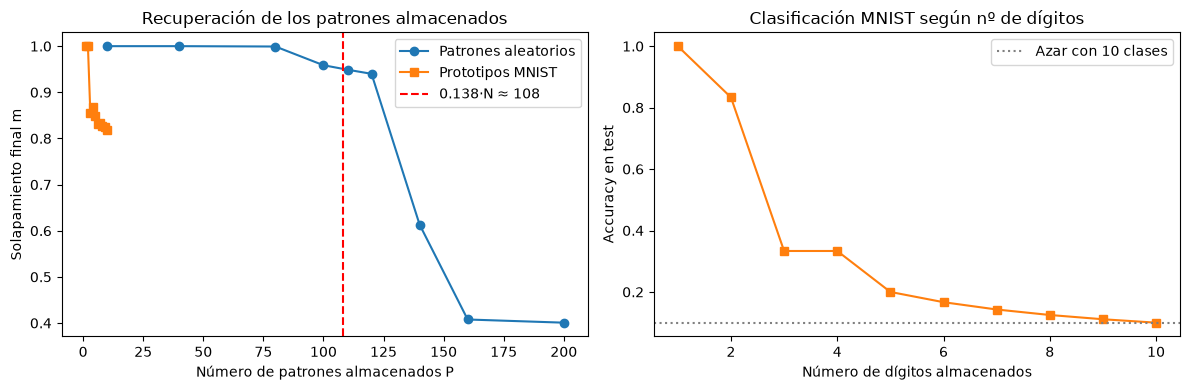

In [18]:
# Patrones aleatorios (lo que supone la teoría)
rng = np.random.default_rng(42)
P_aleatorios = [10, 40, 80, 100, 110, 120, 140, 160, 200]
recuperacion_aleatorios = []
for P in P_aleatorios:
    R = rng.choice([-1, 1], size=(P, N))
    W_R = entrenar_hebb(R)
    m = [R[j] @ recuperar(W_R, R[j]) / N for j in range(10)]
    recuperacion_aleatorios.append(np.mean(m))

# Prototipos MNIST: guardamos 1, 2, ..., 10 dígitos
P_mnist = range(1, 11)
recuperacion_mnist = []
precision_mnist = []
for k in P_mnist:
    W_k = entrenar_hebb(prototipos[:k])
    m = [prototipos[j] @ recuperar(W_k, prototipos[j]) / N for j in range(k)]
    recuperacion_mnist.append(np.mean(m))
    mascara = y_test < k
    pred = [clasificar(recuperar(W_k, x), prototipos[:k], np.arange(k)) for x in X_test[mascara]]
    precision_mnist.append(np.mean(np.array(pred) == y_test[mascara]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(P_aleatorios, recuperacion_aleatorios, 'o-', label="Patrones aleatorios")
axes[0].plot(P_mnist, recuperacion_mnist, 's-', label="Prototipos MNIST")
axes[0].axvline(0.138 * N, color='red', linestyle='--', label="0.138·N ≈ 108")
axes[0].set_xlabel("Número de patrones almacenados P")
axes[0].set_ylabel("Solapamiento final m")
axes[0].set_title("Recuperación de los patrones almacenados")
axes[0].legend()
axes[1].plot(P_mnist, precision_mnist, 's-', color='tab:orange')
axes[1].axhline(1 / 10, color='gray', linestyle=':', label="Azar con 10 clases")
axes[1].set_xlabel("Número de dígitos almacenados")
axes[1].set_ylabel("Accuracy en test")
axes[1].set_title("Clasificación MNIST según nº de dígitos")
axes[1].legend()
plt.tight_layout()
plt.show()


#### Discusión

Según la teoría, una red de Hopfield con la regla de Hebb puede guardar unos 0.138·N patrones. Con N = 784 neuronas serían unos 108 patrones. Si se guardan más, los patrones se interfieren entre ellos y dejan de ser estables.

En nuestro caso hemos guardado 70 patrones (las imágenes de entrenamiento), que son menos de 108. Aun así, ninguno de los 70 es un punto fijo de la red: todos ellos, y también las 30 imágenes de test, acaban en el mismo estado espurio. Por eso la accuracy es 0.10 con cualquier nivel de ruido y en la matriz de confusión solo hay una columna con valores.

Con patrones aleatorios sí se cumple la teoría: hasta P ≈ 120 la red recupera los patrones casi perfectamente (m ≥ 0.94), con P = 140 (P/N ≈ 0.18) baja a m = 0.61 y con 160-200 ya no los recupera (m ≈ 0.4).

Con MNIST la red falla mucho antes, ya que solo funciona bien con 2 patrones. Con 3 dígitos los prototipos ya no son estables (m = 0.86), y con los 10 dígitos todas las imágenes de test acaban en el mismo estado espurio, que es una mezcla de varios dígitos, con una accuracy del 10 %, igual que si eligiéramos al azar. Es decir, aunque 10 patrones son muchos menos que 108, la red no es capaz de guardarlos.

Esto pasa porque el valor de 0.138·N solo es válido para patrones aleatorios que no estén correlacionados (con un solapamiento cercano a 0). Los dígitos de MNIST están muy correlacionados entre sí (solapamiento medio de 0.74), porque todos tienen el fondo negro y el trazo en el centro. Con la regla de Hebb, la interferencia entre patrones depende de ese solapamiento, por lo que la capacidad real baja de unos 108 patrones a unos 2.

Para mejorarlo hay que tener en cuenta la correlación entre los patrones. Con la regla de proyección (sección 2.5), el 100 % de los patrones son puntos fijos, se recuperan aunque tengan un 20 % de bits invertidos y la accuracy sube a 0.47 (0.33 con un 20 % de ruido). Otras opciones serían usar una red de Hopfield moderna o aplicar PCA antes para reducir la correlación entre los dígitos.


## 3. Conclusiones

#### Resumen de resultados

| Experimento | Resultado |
|---|---|
| Accuracy con la regla de Hebb (70 patrones guardados) | 0.10 (igual que el azar) |
| Accuracy con Hebb y 5 %, 10 % y 20 % de ruido | 0.10 en todos los casos |
| Patrones de entrenamiento que son puntos fijos (Hebb) | 0 % |
| Accuracy con la regla de proyección | 0.47 (0.37, 0.37 y 0.33 con 5 %, 10 % y 20 % de ruido) |
| Patrones de entrenamiento que son puntos fijos (proyección) | 100 % |
| Capacidad teórica 0.138·N | unos 108 patrones |
| Capacidad con patrones aleatorios | unos 120 patrones |
| Capacidad con prototipos de MNIST | unos 2 patrones |

#### Análisis de los resultados

- Creemos que la implementación es correcta, ya que la energía nunca aumenta, la red converge en 2-3 barridos y con patrones aleatorios se cumple la capacidad teórica. Por tanto, los malos resultados no vienen de un error en el código, sino de una limitación del propio modelo.
- La red de Hopfield con la regla de Hebb no es capaz de clasificar MNIST. Todas las imágenes, tanto de entrenamiento como de test, acaban en el mismo estado espurio, así que la red siempre predice la misma clase.
- El problema es que los dígitos están muy correlacionados. La regla de Hebb supone que los patrones no están correlacionados, pero los dígitos de MNIST comparten la mayoría de los píxeles (el fondo negro y el trazo en el centro), con un solapamiento medio de 0.74. Esta parte común es la que domina en la matriz de pesos, y la red se comporta como si solo hubiera guardado un "dígito medio".
- La capacidad teórica de 0.138·N no sirve para datos reales como MNIST. Guardamos 70 patrones, menos de los 108 teóricos, y no se quedó estable ninguno. En la práctica, con MNIST la red solo puede guardar unos 2 patrones.
- En cuanto al ruido, con Hebb no cambia nada porque todas las entradas acaban en el mismo atractor. Con la regla de proyección, los patrones guardados se recuperan bien incluso con un 20 % de ruido, pero la accuracy en test baja de 0.47 a 0.33 al aumentar el ruido.

#### Ventajas

- Es un modelo sencillo y fácil de entender gracias a la función de energía.
- Con la regla de Hebb el entrenamiento se hace en un solo paso, sin tener que iterar.
- Si los pesos son simétricos y la dinámica es asíncrona, la red siempre converge.
- Si los patrones son distintos entre sí, aguanta bien el ruido (lo hemos visto con los patrones aleatorios y con la regla de proyección).

#### Limitaciones

- Puede guardar pocos patrones y le afecta mucho que estén correlacionados, lo que hace que aparezcan estados espurios.
- Al binarizar las imágenes se pierde información (los niveles de gris).
- Funciona más como una memoria que como un clasificador: solo recuerda los ejemplos que ha guardado y no generaliza.
- La matriz de pesos tiene N² = 614.656 elementos, y cada barrido necesita del orden de N² operaciones.

#### Posibles mejoras

- Regla de proyección (pseudoinversa): la hemos probado en la sección 2.5 y consigue que todos los patrones guardados sean estables.
- Red de Hopfield moderna: usa otra función de energía con la que la capacidad es mucho mayor y distingue mejor patrones parecidos.
- Preprocesamiento: centrar los patrones (restar el patrón medio) o aplicar PCA para quitar la parte común de los dígitos y reducir la correlación entre ellos.

## 4. Referencias

Haykin, S. (2009). *Neural networks and learning machines* (3rd ed.). Pearson.

Hopfield, J. J. (1982). Neural networks and physical systems with emergent collective computational abilities. *Proceedings of the National Academy of Sciences, 79*(8), 2554–2558. https://doi.org/10.1073/pnas.79.8.2554

LeCun, Y., Cortes, C., & Burges, C. J. C. (1998). *The MNIST database of handwritten digits*. http://yann.lecun.com/exdb/mnist/